# Pilar 3 — Integração com outros modais 

### Os dados, em uma tabela

| Dado | O que é | Por que importa |
|---|---|---|
| **Bairros** | limites dos bairros | é a "linha" da nossa tabela: tudo é somado por bairro |
| **Ciclovias implantadas** | o que a EPTC já construiu (~95 km) | mostra onde **já tem** ciclovia |
| **Rede PDCI** | plano de ciclovias da cidade (feitas + previstas) | mostra o que **falta construir** |
| **Corredores de ônibus** | vias com prioridade para ônibus | onde passa **muita gente** |
| **Paradas de ônibus** | ~5,9 mil paradas | mais paradas = mais **demanda** |
| **BikePoa** | estações de bicicleta compartilhada | gente que **já usa** bicicleta |
| **Bicicletários** | locais para guardar bicicleta | destinos e integração com ônibus |

In [98]:
from pathlib import Path

import folium
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "1_raw" / "pilar3"
if not RAW.exists():
    RAW = ROOT / "data" / "1_raw"
DONE = ROOT / "data" / "3_done"
DONE.mkdir(parents=True, exist_ok=True)

CRS_GEO = 4326   # graus (para mapas)
CRS_M = 31982    # metros (para medir km e km²)

print("Lendo dados de:", RAW)

Lendo dados de: /Users/aluno-29/Desktop/eld_dataset/data/1_raw/pilar3


## 1. Carregar
Procura cada arquivo pelo começo do nome (a data no nome muda quando a EPTC atualiza).

In [99]:
def carregar(prefixo):
    achados = sorted(RAW.glob(f"{prefixo}*.geojson"))
    if not achados:
        raise FileNotFoundError(f"Não achei '{prefixo}*.geojson' em {RAW}")
    g = gpd.read_file(achados[-1])
    print(f"{achados[-1].name}: {len(g)} linhas")
    return g


brutos = {
    "bairros": carregar("Bairros"),
    "ciclovias": carregar("CicloviasImplantadas"),
    "rede_pdci": carregar("RedeCicloviariaPDCI"),
    "paradas": carregar("Paradas"),
    "corredores": carregar("CorredoresFaixasExclusivas"),
    "paraciclos": carregar("ParaciclosImplantados"),
    "bikepoa": carregar("BikePoa"),
}

Bairros_LC12112_16.geojson: 128 linhas
CicloviasImplantadas_20261112.geojson: 97 linhas
RedeCicloviariaPDCI_20251202.geojson: 4144 linhas
Paradas_20261112.geojson: 5913 linhas
CorredoresFaixasExclusivas_20260909.geojson: 47 linhas
ParaciclosImplantados_20261112.geojson: 47 linhas
BikePoa_20261112.geojson: 90 linhas


## 2. Limpar
Em cada camada: fica só com as colunas úteis (com nome em minúsculo), tira linhas sem desenho, repetidas e fora de Porto Alegre.

In [100]:
COLUNAS = {
    "bairros": {"NOME": "bairro"},
    "ciclovias": {"NOME": "nome", "TIPO": "tipo"},
    "rede_pdci": {"NOME": "nome", "SITUACAO": "situacao", "HIERARQUIA": "hierarquia"},
    "paradas": {"PLOGR": "logradouro", "LINHAS": "linhas", "TERMINAL": "terminal"},
    "corredores": {"NMIDELO": "logradouro", "TRANSPO": "transporte", "SITUACA": "situacao"},
    "paraciclos": {"Name": "nome", "Quantidade": "quantidade"},
    "bikepoa": {"NOME": "nome", "VAGAS_DOCK": "vagas"},
}

camadas = {}
for nome, g in brutos.items():
    mapa = {c: n for c, n in COLUNAS[nome].items() if c in g.columns}
    camadas[nome] = g[list(mapa) + ["geometry"]].rename(columns=mapa).copy()

# Limite de Porto Alegre (união dos bairros + 200 m de folga)
_b = camadas["bairros"].to_crs(CRS_M)
_uniao = _b.geometry.make_valid().union_all() if hasattr(_b.geometry, "union_all") else _b.geometry.make_valid().unary_union
limite_poa = gpd.GeoSeries([_uniao.buffer(200)], crs=CRS_M).to_crs(CRS_GEO).iloc[0]


def limpar(g, nome):
    n0 = len(g)
    g = g[~(g.geometry.isna() | g.geometry.is_empty)].copy().to_crs(CRS_GEO)
    for c in g.columns:                      # texto vazio vira vazio de verdade
        if c != "geometry" and g[c].dtype == object:
            g[c] = g[c].apply(lambda v: None if isinstance(v, str) and v.strip().lower() in ("", "nan", "none") else (v.strip() if isinstance(v, str) else v))
    chave = g.drop(columns="geometry").astype(str)
    chave["_g"] = g.geometry.to_wkb()
    g = g[~chave.duplicated()]
    g = g[g.intersects(limite_poa)].reset_index(drop=True)
    print(f"{nome}: {n0} -> {len(g)} linhas")
    return g


limpas = {n: limpar(g, n) for n, g in camadas.items() if n != "bairros"}
limpas["bicicletarios"] = limpas.pop("paraciclos")

ciclovias: 97 -> 97 linhas
rede_pdci: 4144 -> 4120 linhas
paradas: 5913 -> 5871 linhas
corredores: 47 -> 47 linhas
paraciclos: 47 -> 47 linhas
bikepoa: 90 -> 90 linhas


## 3. Ajustes simples
- **Situação da rede PDCI:** o arquivo tem 8 jeitos de escrever a situação. Juntamos em 4: `existente`, `em obra/projeto`, `planejado` e `outros`.
- **Comprimento:** calculado em km a partir do desenho.
- **Bairros:** o arquivo tem 128 pedaços para ~94 bairros e a área vem zerada. Juntamos os pedaços e calculamos a área em km².
- **Bairro das paradas:** ~40% vêm sem bairro. Descobrimos o bairro pela **localização**.

In [101]:
def grupo_situacao(v):
    if v is None or pd.isna(v):
        return "outros"
    s = str(v).strip().upper().replace("_", " ")
    if s.startswith("CONCLUIDO"):
        return "existente"
    if s in ("OBRA", "PROJETO", "CICLORROTA PROJETO"):
        return "em obra/projeto"
    if s == "PLANO":
        return "planejado"
    return "outros"


pdci = limpas["rede_pdci"]
pdci["grupo"] = pdci["situacao"].apply(grupo_situacao)

for nome in ("ciclovias", "rede_pdci", "corredores"):
    limpas[nome]["km"] = limpas[nome].to_crs(CRS_M).length / 1000

# Bairros: 1 linha por bairro, com área em km²
_b["geometry"] = _b.geometry.make_valid()
bairros_m = _b.dissolve(by="bairro", as_index=False)
bairros_m["area_km2"] = bairros_m.geometry.area / 1e6
bairros_m = bairros_m[["bairro", "area_km2", "geometry"]]
bairros_geo = bairros_m.to_crs(CRS_GEO)


def com_bairro(g):
    """Acrescenta a coluna `bairro_geo` (em que bairro o ponto está)."""
    j = gpd.sjoin(g, bairros_geo[["bairro", "geometry"]].rename(columns={"bairro": "bairro_geo"}),
                  how="left", predicate="within")
    return j[~j.index.duplicated()].drop(columns="index_right")


for nome in ("paradas", "bikepoa", "bicicletarios"):
    limpas[nome] = com_bairro(limpas[nome])

print(f"{len(bairros_m)} bairros | área total {bairros_m['area_km2'].sum():.0f} km²")
print("Km por camada:", {n: round(limpas[n]['km'].sum(), 1) for n in ('ciclovias', 'rede_pdci', 'corredores')})

94 bairros | área total 472 km²
Km por camada: {'ciclovias': np.float64(95.2), 'rede_pdci': np.float64(533.6), 'corredores': np.float64(108.0)}


## 4. Ver os dados
### 4.1 Mapa geral
Verde = ciclovia que já existe · cinza = PDCI ainda a construir · laranja = corredor de ônibus · azul = paradas · roxo = BikePoa · vermelho = bicicletários.

**Observe:** onde há muita parada (azul) e pouca ciclovia (verde)?

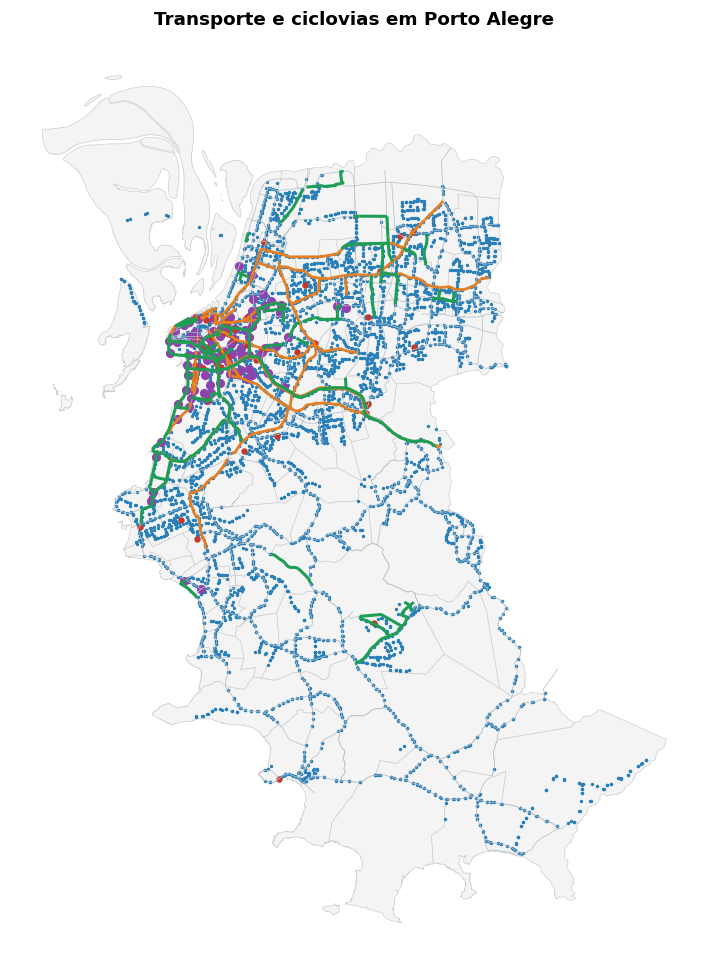

In [102]:
fig, ax = plt.subplots(figsize=(10, 11))
bairros_geo.plot(ax=ax, color="#f4f4f4", edgecolor="#cccccc", linewidth=0.4)
pdci[pdci["grupo"].isin(["em obra/projeto", "planejado"])].plot(ax=ax, color="#b8c0c8", linewidth=0.5)
limpas["corredores"].plot(ax=ax, color="#e67e22", linewidth=1.8)
limpas["ciclovias"].plot(ax=ax, color="#1e9e55", linewidth=2)
limpas["paradas"].plot(ax=ax, color="#2980b9", markersize=1.5)
limpas["bikepoa"].plot(ax=ax, color="#8e44ad", markersize=25)
limpas["bicicletarios"].plot(ax=ax, color="#c0392b", markersize=10)
ax.set_title("Transporte e ciclovias em Porto Alegre")
ax.set_axis_off()
plt.show()

### 4.2 Quanto do plano (PDCI) já foi construído?


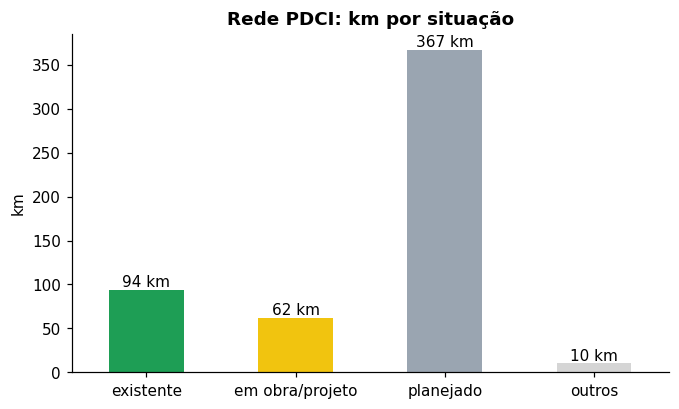

In [103]:
ordem = ["existente", "em obra/projeto", "planejado", "outros"]
cores = ["#1e9e55", "#f1c40f", "#9aa5b1", "#d5d5d5"]
km_grupo = pdci.groupby("grupo")["km"].sum().reindex(ordem)

ax = km_grupo.plot.bar(color=cores, rot=0, figsize=(7, 4))
for i, v in enumerate(km_grupo.values):
    ax.text(i, v, f"{v:,.0f} km", ha="center", va="bottom")
ax.set_title("Rede PDCI: km por situação")
ax.set_xlabel("")
ax.set_ylabel("km")
plt.show()

### 4.3 Bairros com mais paradas por km²
Usamos **por km²** (e não só a contagem) porque bairro grande sempre tem mais paradas, e isso não quer dizer mais demanda.

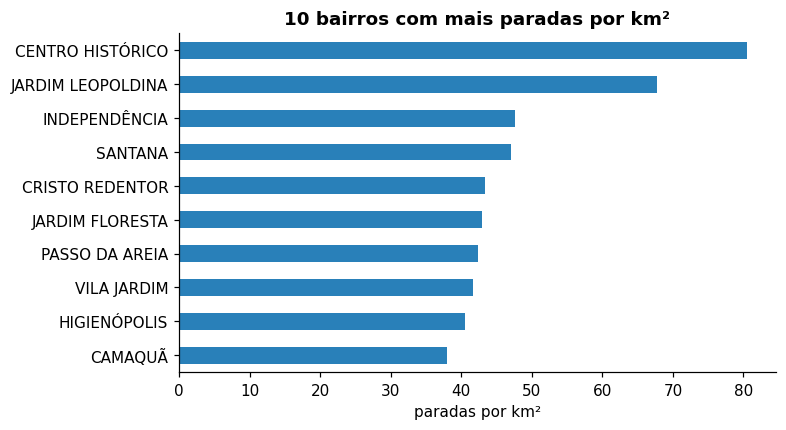

In [104]:
area = bairros_m.set_index("bairro")["area_km2"]
dens = (limpas["paradas"].groupby("bairro_geo").size() / area).dropna().sort_values().tail(10)

ax = dens.plot.barh(color="#2980b9", figsize=(7, 4))
ax.set_title("10 bairros com mais paradas por km²")
ax.set_xlabel("paradas por km²")
ax.set_ylabel("")
plt.show()

## 5. Tabela por bairro (a base do dataset)
Uma linha por bairro. Cada coluna é uma informação que o modelo poderá usar:

| Coluna | O que é |
|---|---|
| `area_km2` | tamanho do bairro |
| `km_ciclovia` | km de ciclovia já construída |
| `km_pdci_a_construir` | km do plano ainda não construídos |
| `km_corredor` | km de corredor de ônibus em operação |
| `n_paradas` | número de paradas |
| `n_bikepoa` | estações BikePoa |
| `n_bicicletarios` | bicicletários |
| `paradas_por_km2`, `km_ciclovia_por_km2` | as mesmas, divididas pela área |

Bairro sem nada recebe **0** (não ter também é informação).

In [105]:
def km_por_bairro(g):
    """Soma os km de linha dentro de cada bairro (a linha é cortada na divisa)."""
    if len(g) == 0:
        return pd.Series(dtype=float)
    corte = gpd.overlay(g.to_crs(CRS_M)[["geometry"]], bairros_m[["bairro", "geometry"]],
                        how="intersection", keep_geom_type=True)
    return (corte.length / 1000).groupby(corte["bairro"]).sum()


corr_ativos = limpas["corredores"][limpas["corredores"]["situacao"].fillna("").str.upper() != "INATIVA"]

feat = bairros_m[["bairro", "area_km2"]].set_index("bairro")
feat["km_ciclovia"] = km_por_bairro(limpas["ciclovias"])
feat["km_pdci_a_construir"] = km_por_bairro(pdci[pdci["grupo"].isin(["em obra/projeto", "planejado"])])
feat["km_corredor"] = km_por_bairro(corr_ativos)
feat["n_paradas"] = limpas["paradas"].groupby("bairro_geo").size()
feat["n_bikepoa"] = limpas["bikepoa"].groupby("bairro_geo").size()
feat["n_bicicletarios"] = limpas["bicicletarios"].groupby("bairro_geo").size()
feat = feat.fillna(0)
feat["paradas_por_km2"] = feat["n_paradas"] / feat["area_km2"]
feat["km_ciclovia_por_km2"] = feat["km_ciclovia"] / feat["area_km2"]

feat_geo = bairros_geo[["bairro", "geometry"]].merge(feat.reset_index(), on="bairro")
display(feat.sort_values("n_paradas", ascending=False).head(10).round(2))

,area_km2,km_ciclovia,km_pdci_a_construir,km_corredor,n_paradas,n_bikepoa,n_bicicletarios,paradas_por_km2,km_ciclovia_por_km2
bairro,,,,,,,,,
LOMBA DO PINHEIRO,29.73,1.53,35.23,0.28,292,0.00,0.00,9.82,0.05
SARANDI,24.56,6.45,26.92,6.79,265,0.00,2.00,10.79,0.26
PARTENON,6.33,2.01,8.27,12.87,198,0.00,0.00,31.26,0.32
CENTRO HISTÓRICO,2.43,3.47,9.76,5.12,196,10.00,6.00,80.55,1.43
VILA NOVA,12.03,1.16,15.48,0.89,175,0.00,0.00,14.55,0.10
RESTINGA,20.09,8.52,8.59,0.00,164,0.00,1.00,8.16,0.42
HÍPICA,10.32,0.00,13.34,0.00,134,0.00,0.00,12.98,0.00
SANTA ROSA DE LIMA,5.50,0.00,7.93,0.00,116,0.00,0.00,21.11,0.00
SANTA TEREZA,4.51,2.43,1.27,2.52,115,0.00,0.00,25.47,0.54


### 5.1 Onde falta ciclovia?
Cada ponto é um bairro. **Direita** = mais paradas por km² (mais demanda). **Embaixo** = menos ciclovia. Os pontos em **vermelho** são os 8 com maior diferença entre as duas coisas.

> É uma **conversa inicial**, não o resultado do modelo: usa só duas informações e ainda não considera população, renda ou segurança.

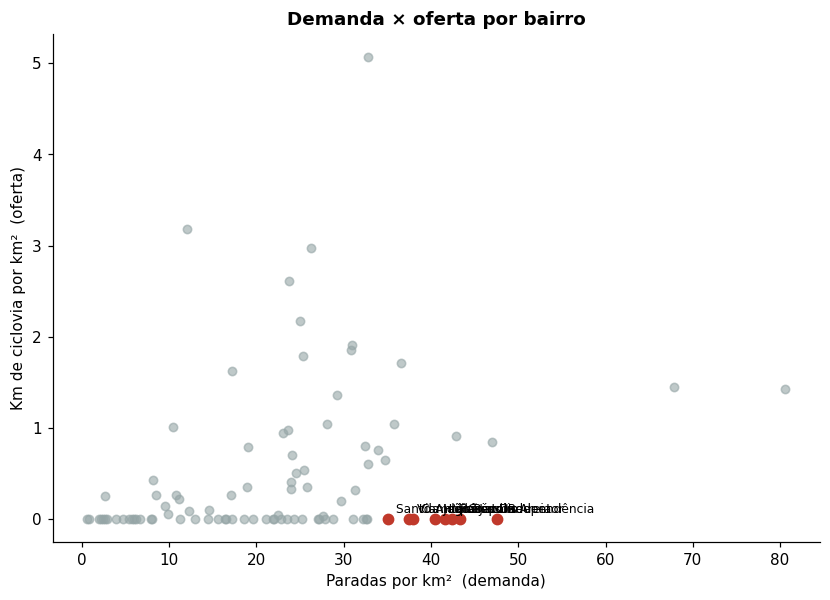

In [106]:
d = feat.copy()
d["lacuna"] = d["paradas_por_km2"].rank(pct=True) - d["km_ciclovia_por_km2"].rank(pct=True)
top = d.sort_values("lacuna", ascending=False).head(8)

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(d["paradas_por_km2"], d["km_ciclovia_por_km2"], color="#95a5a6", alpha=0.6, s=30)
ax.scatter(top["paradas_por_km2"], top["km_ciclovia_por_km2"], color="#c0392b", s=45)
for nome, r in top.iterrows():
    ax.annotate(nome.title(), (r["paradas_por_km2"], r["km_ciclovia_por_km2"]),
                xytext=(5, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("Paradas por km²  (demanda)")
ax.set_ylabel("Km de ciclovia por km²  (oferta)")
ax.set_title("Demanda × oferta por bairro")
plt.show()

## 7. Salvar
Gera `pilar3_features_bairro.csv` (a tabela da seção 5) e os `.geojson` das camadas em `data/3_done/`.

In [108]:
feat.reset_index().to_csv(DONE / "pilar3_features_bairro.csv", index=False)
feat_geo.to_file(DONE / "pilar3_features_bairro.geojson", driver="GeoJSON")

for nome in ("ciclovias", "rede_pdci", "paradas", "corredores", "bikepoa", "bicicletarios"):
    limpas[nome].to_file(DONE / f"pilar3_{nome}.geojson", driver="GeoJSON")
print("Arquivos salvos em", DONE)

camadas_salvar = {
    "features_bairro": feat_geo,
    "bairros": bairros_geo,
    "ciclovias": limpas["ciclovias"],
    "rede_pdci": limpas["rede_pdci"],
    "paradas": limpas["paradas"],
    "corredores": limpas["corredores"],
    "bikepoa": limpas["bikepoa"],
    "bicicletarios": limpas["bicicletarios"],
}

for nome, g in camadas_salvar.items():
    g.to_file(DONE / f"pilar3_{nome}.geojson", driver="GeoJSON")   # com o desenho
    tabela = g.drop(columns="geometry")
    if (g.geom_type == "Point").all():                              # pontos: lat e lon em colunas
        tabela["lat"] = g.geometry.y.round(6)
        tabela["lon"] = g.geometry.x.round(6)
    tabela.to_csv(DONE / f"pilar3_{nome}.csv", index=False)        # só a tabela
    print(f"{nome}: {len(g)} linhas -> .geojson e .csv")



Arquivos salvos em /Users/aluno-29/Desktop/eld_dataset/data/3_done
features_bairro: 94 linhas -> .geojson e .csv
bairros: 94 linhas -> .geojson e .csv
ciclovias: 97 linhas -> .geojson e .csv
rede_pdci: 4120 linhas -> .geojson e .csv
paradas: 5871 linhas -> .geojson e .csv
corredores: 47 linhas -> .geojson e .csv
bikepoa: 90 linhas -> .geojson e .csv
bicicletarios: 47 linhas -> .geojson e .csv
